In [ ]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 70)
print("SEQUENTIAL CNN — CPU ENVIRONMENT SETUP")
print("=" * 70)

print("TensorFlow version :", tf.__version__)
print("GPU available      :", tf.config.list_physical_devices("GPU"))
print("Using device       : CPU")
print("Random seed        :", SEED)

print("=" * 70)

SEQUENTIAL CNN — CPU ENVIRONMENT SETUP
TensorFlow version : 2.20.0
GPU available      : []
Using device       : CPU
Random seed        : 42


In [3]:
import zipfile
print("zipfile imported successfully")

zipfile imported successfully


In [ ]:
import os
import shutil
import zipfile

zip_path = "/content/drive/MyDrive/data_classification1.zip"
extract_path = "/content/traffic_sign_dataset"

if os.path.exists(extract_path):
    shutil.rmtree(extract_path)


os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

base_dir = os.path.join(
    extract_path,
    "data_classification1"
)

train_dir = os.path.join(
    base_dir,
    "train"
)

test_dir = os.path.join(
    base_dir,
    "test"
)

print("=" * 70)
print("DATASET EXTRACTION VERIFICATION")
print("=" * 70)

print("Train directory exists :", os.path.exists(train_dir))
print("Test directory exists  :", os.path.exists(test_dir))

if os.path.exists(train_dir):
    print(
        "Train files            :",
        sum(
            len(files)
            for _, _, files in os.walk(train_dir)
        )
    )

if os.path.exists(test_dir):
    print(
        "Test files             :",
        sum(
            len(files)
            for _, _, files in os.walk(test_dir)
        )
    )

print("=" * 70)

DATASET EXTRACTION VERIFICATION
Train directory exists : True
Test directory exists  : True
Train files            : 1927
Test files             : 409


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 28
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    color_mode="rgb",
    shuffle=True
)


val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    color_mode="rgb",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    color_mode="rgb",
    shuffle=False
)


normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prefetch
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("\n================ DATASET SUMMARY ================")
print("Training batches   :", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches :", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches       :", tf.data.experimental.cardinality(test_ds).numpy())

# Check one batch
images, labels = next(iter(train_ds))

print("\nImage batch shape :", images.shape)
print("Label batch shape :", labels.shape)
print("Image value range:", float(tf.reduce_min(images)),
      "to", float(tf.reduce_max(images)))

Found 1927 files belonging to 28 classes.
Using 1542 files for training.
Found 1927 files belonging to 28 classes.
Using 385 files for validation.
Found 409 files belonging to 28 classes.

================ DATASET SUMMARY ================
Training batches   : 49
Validation batches : 13
Test batches       : 13

Image batch shape : (32, 224, 224, 3)
Label batch shape : (32, 28)
Image value range: 0.0 to 1.0


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([

    # Input
    layers.Input(shape=(224, 224, 3)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 4
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Classification head
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="Sequential_CNN_TSR")


model.summary()

print("\n================================================")
print("Sequential CNN created successfully")
print("Input size :", (224, 224, 3))
print("Classes    :", NUM_CLASSES)
print("================================================")

Model: "Sequential_CNN_TSR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 426,844 (1.63 MB)

 Trainable params: 425,884 (1.62 MB)

 Non-trainable params: 960 (3.75 KB)


Sequential CNN created successfully
Input size : (224, 224, 3)
Classes    : 28


In [ ]:
import tensorflow as tf
import numpy as np
import random

SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)


model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("================================================")
print("SEQUENTIAL CNN COMPILED")
print("================================================")
print("Optimizer     : Adam")
print("Learning Rate : 0.001")
print("Loss          : Categorical Crossentropy")
print("Metric        : Accuracy")
print("Random Seed   :", SEED)
print("================================================")

SEQUENTIAL CNN COMPILED
Optimizer     : Adam
Learning Rate : 0.001
Loss          : Categorical Crossentropy
Metric        : Accuracy
Random Seed   : 42


In [11]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("GPU is available ✅")
else:
    print("GPU is NOT available ❌")

TensorFlow: 2.20.0
GPU devices: []
GPU is NOT available ❌


In [ ]:
print("Model exists   :", "model" in globals())
print("History exists :", "history" in globals())

if "history" in globals():
    print("\nTraining epochs recorded:",
          len(history.history.get("loss", [])))

    print("Final train accuracy:",
          history.history["accuracy"][-1])

    print("Final validation accuracy:",
          history.history["val_accuracy"][-1])

    print("Best validation accuracy:",
          max(history.history["val_accuracy"]))

Model exists   : True
History exists : True

Training epochs recorded: 15
Final train accuracy: 0.774319052696228
Final validation accuracy: 0.7714285850524902
Best validation accuracy: 0.7714285850524902


In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n================================================")
print("SEQUENTIAL CNN FINAL TEST RESULT")
print("================================================")
print("Test Loss     :", round(test_loss, 4))
print("Test Accuracy : {:.2f}%".format(test_accuracy * 100))
print("Test Images   : 409")
print("================================================")

13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.6137 - loss: 1.1452

SEQUENTIAL CNN FINAL TEST RESULT
Test Loss     : 1.1452
Test Accuracy : 61.37%
Test Images   : 409


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Collect predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    true_labels = np.argmax(labels.numpy(), axis=1)
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(true_labels)
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
weighted_precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
weighted_recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("\n================================================")
print("SEQUENTIAL CNN FINAL TEST METRICS")
print("================================================")
print("Test Images          :", len(y_true))
print("Accuracy             : {:.2f}%".format(accuracy * 100))
print("Weighted Precision   : {:.4f}".format(weighted_precision))
print("Weighted Recall      : {:.4f}".format(weighted_recall))
print("Weighted F1          : {:.4f}".format(weighted_f1))
print("================================================")


SEQUENTIAL CNN FINAL TEST METRICS
Test Images          : 409
Accuracy             : 61.37%
Weighted Precision   : 0.7010
Weighted Recall      : 0.6137
Weighted F1          : 0.6116


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import os

# Get class names directly from test directory
class_names = sorted([
    folder for folder in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, folder))
])

print("Number of classes:", len(class_names))
print("Class names:", class_names)

# Classification report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\n================================================")
print("SEQUENTIAL CNN CLASSIFICATION REPORT")
print("================================================")
print(report)

# Save report
report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    "SequentialCNN_Classification_Report.csv"
)

print("================================================")
print("Classification report saved:")
print("SequentialCNN_Classification_Report.csv")
print("================================================")

Number of classes: 28
Class names: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '3', '4', '5', '6', '7', '8', '9']

SEQUENTIAL CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9091    0.9091    0.9091        22
           1     1.0000    0.5000    0.6667         2
          10     0.8750    0.6364    0.7368        11
          11     0.0000    0.0000    0.0000         8
          12     1.0000    0.3333    0.5000         3
          13     1.0000    0.3333    0.5000         3
          14     0.0000    0.0000    0.0000         3
          15     0.8519    0.8846    0.8679        26
          16     1.0000    0.5000    0.6667         2
          17     0.4000    0.7600    0.5241        50
          18     0.4375    0.6364    0.5185        11
          19     0.7500    0.5000    0.6000        18
           2     0.4783    0.6471    0.5500        17
          2

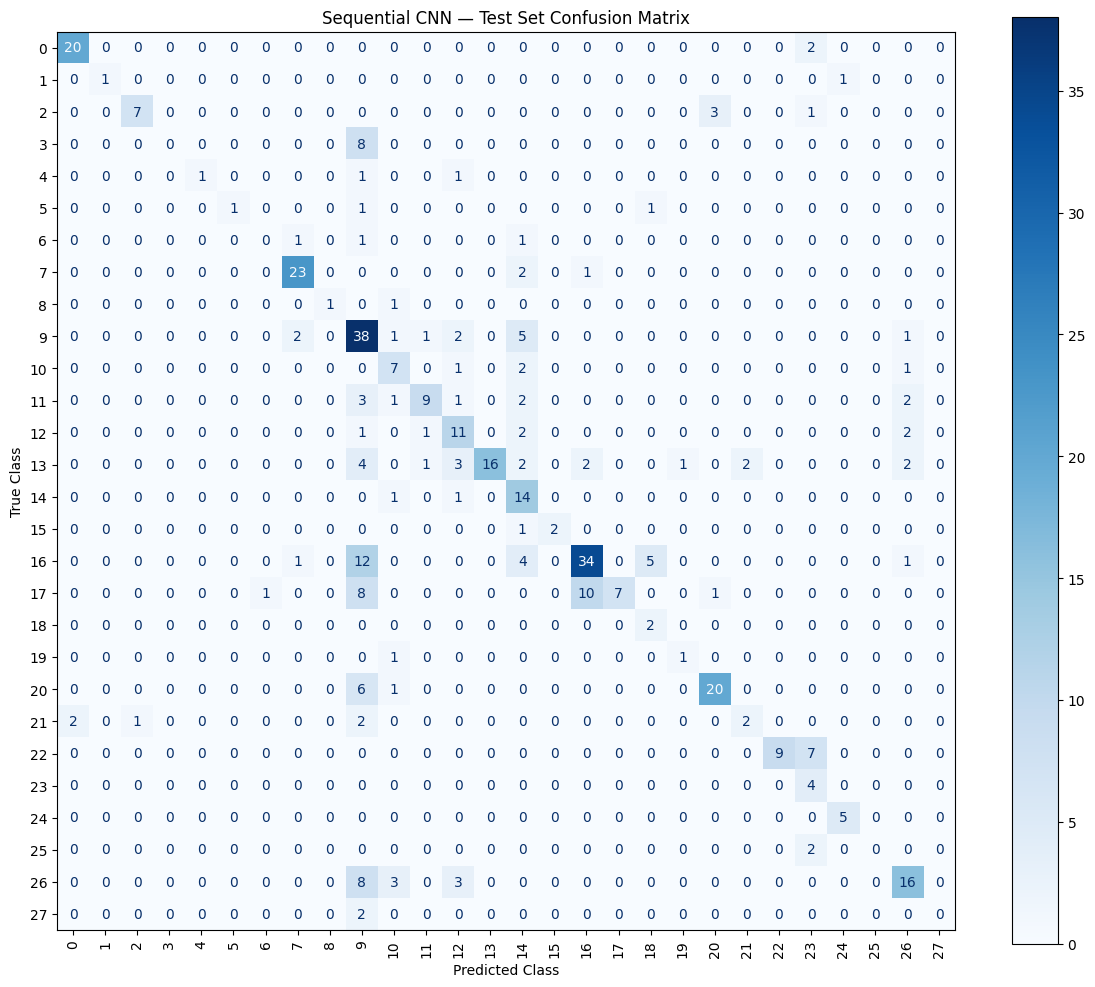


CONFUSION MATRIX CREATED
Shape : (28, 28)
Saved : SequentialCNN_Confusion_Matrix.png


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)


fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(i) for i in range(NUM_CLASSES)]
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=True
)

plt.title("Sequential CNN — Test Set Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

plt.savefig(
    "SequentialCNN_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n================================================")
print("CONFUSION MATRIX CREATED")
print("================================================")
print("Shape :", cm.shape)
print("Saved : SequentialCNN_Confusion_Matrix.png")
print("================================================")

In [ ]:
import time
import numpy as np
import tensorflow as tf

benchmark_images, _ = next(iter(test_ds))

WARMUP_RUNS = 10
TIMED_RUNS = 50

print("Running warm-up...")

for _ in range(WARMUP_RUNS):
    _ = model(benchmark_images, training=False)

_ = model(benchmark_images, training=False).numpy()

times = []

print("Running timed inference...")

for _ in range(TIMED_RUNS):
    start = time.perf_counter()

    predictions = model(
        benchmark_images,
        training=False
    )

    _ = predictions.numpy()

    end = time.perf_counter()

    times.append(end - start)

times = np.array(times)

STABLE_TIMES = times[5:]

mean_batch_time = np.mean(STABLE_TIMES)
median_batch_time = np.median(STABLE_TIMES)

batch_size = benchmark_images.shape[0]

mean_per_image = mean_batch_time / batch_size
median_per_image = median_batch_time / batch_size

throughput = batch_size / mean_batch_time

print("\n================================================")
print("SEQUENTIAL CNN — INFERENCE BENCHMARK")
print("================================================")
print("Device              : CPU")
print("Batch size          :", batch_size)
print("Warm-up runs        :", WARMUP_RUNS)
print("Timed runs          :", TIMED_RUNS)
print("Stable timed runs   :", len(STABLE_TIMES))
print("------------------------------------------------")
print("Mean batch latency  : {:.6f} sec".format(mean_batch_time))
print("Median batch latency: {:.6f} sec".format(median_batch_time))
print("Mean per-image      : {:.3f} ms".format(
    mean_per_image * 1000
))
print("Median per-image    : {:.3f} ms".format(
    median_per_image * 1000
))
print("Throughput          : {:.2f} images/sec".format(
    throughput
))
print("================================================")

Running warm-up...
Running timed inference...

SEQUENTIAL CNN — INFERENCE BENCHMARK
Device              : CPU
Batch size          : 32
Warm-up runs        : 10
Timed runs          : 50
Stable timed runs   : 45
------------------------------------------------
Mean batch latency  : 2.047199 sec
Median batch latency: 1.786944 sec
Mean per-image      : 63.975 ms
Median per-image    : 55.842 ms
Throughput          : 15.63 images/sec


In [ ]:
import tensorflow as tf
import numpy as np

LAST_CONV_LAYER_NAME = "conv2d_3"


def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name,
    pred_index=None
):
   
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array,
            training=False
        )

        if pred_index is None:
            pred_index = tf.argmax(
                predictions[0]
            )

        class_channel = predictions[:, pred_index]


    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

 
    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy(), int(pred_index.numpy())


print("================================================")
print("Grad-CAM function created")
print("Target layer :", LAST_CONV_LAYER_NAME)
print("================================================")

Grad-CAM function created
Target layer : conv2d_3


In [ ]:
def make_gradcam_heatmap_fixed(
    img_array,
    model,
    last_conv_layer_name,
    pred_index=None
):

    # Build an intermediate model using explicit input tensor
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.layers[-1].output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array,
            training=False
        )

        if pred_index is None:
            pred_index = tf.argmax(
                predictions[0]
            )

        class_channel = predictions[:, pred_index]

    # Gradient of predicted class
    grads = tape.gradient(
        class_channel,
        conv_outputs
    )


    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

   
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy(), int(pred_index.numpy())


print("================================================")
print("FIXED Grad-CAM FUNCTION CREATED")
print("Target layer :", LAST_CONV_LAYER_NAME)
print("================================================")

FIXED Grad-CAM FUNCTION CREATED
Target layer : conv2d_3


SINGLE IMAGE GRAD-CAM VERIFICATION
True class      : 0
Predicted class : 0
Heatmap shape   : (28, 28)
Heatmap min     : 0.0
Heatmap max     : 1.0
Heatmap mean    : 0.06930676102638245
Pixels >= 0.5   : 29
Total pixels    : 784


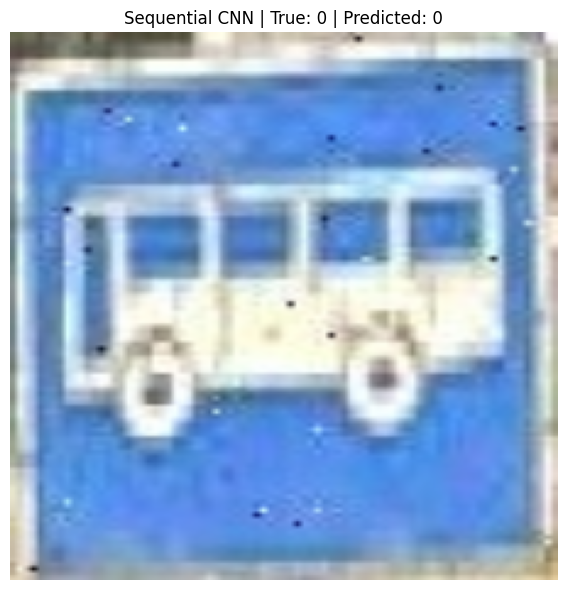

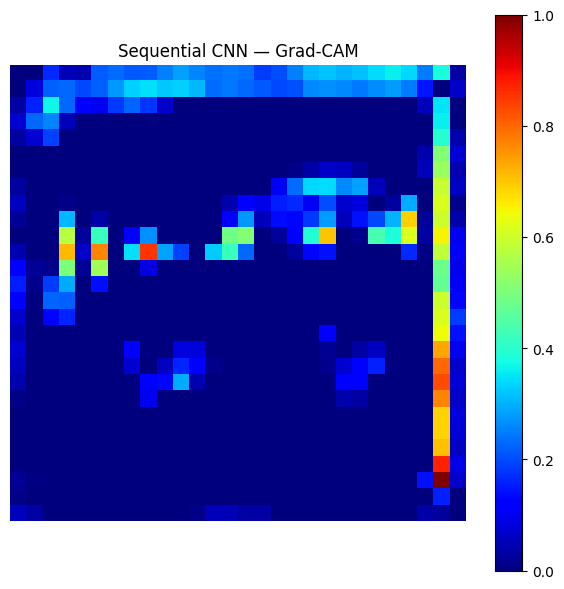

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf


sample_images, sample_labels = next(iter(test_ds))

img = sample_images[0]
true_class = int(tf.argmax(sample_labels[0]).numpy())


img_array = tf.expand_dims(img, axis=0)


heatmap, predicted_class = make_gradcam_heatmap_fixed(
    img_array,
    model,
    LAST_CONV_LAYER_NAME
)

print("================================================")
print("SINGLE IMAGE GRAD-CAM VERIFICATION")
print("================================================")
print("True class      :", true_class)
print("Predicted class :", predicted_class)
print("Heatmap shape   :", heatmap.shape)
print("Heatmap min     :", float(np.min(heatmap)))
print("Heatmap max     :", float(np.max(heatmap)))
print("Heatmap mean    :", float(np.mean(heatmap)))
print("Pixels >= 0.5   :", int(np.sum(heatmap >= 0.5)))
print("Total pixels    :", heatmap.size)
print("================================================")

# Original image
plt.figure(figsize=(6, 6))
plt.imshow(img.numpy())
plt.title(
    f"Sequential CNN | True: {true_class} | Predicted: {predicted_class}"
)
plt.axis("off")
plt.tight_layout()
plt.show()

# Grad-CAM heatmap
plt.figure(figsize=(6, 6))
plt.imshow(heatmap, cmap="jet")
plt.colorbar()
plt.title("Sequential CNN — Grad-CAM")
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
def make_gradcam_heatmap_fixed(
    img_array,
    model,
    last_conv_layer_name,
    pred_index=None
):

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.layers[-1].output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array,
            training=False
        )

        if pred_index is None:
            pred_index = int(
                tf.argmax(predictions[0]).numpy()
            )
        else:
            pred_index = int(pred_index)

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy(), pred_index


print("================================================")
print("GRAD-CAM FUNCTION FIXED")
print("================================================")

GRAD-CAM FUNCTION FIXED


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf

important_pixel_percentages = []
heatmap_intensities = []
predictions_all = []
true_labels_all = []
heatmaps_all = []

image_counter = 0

for images, labels in test_ds:

    # Batch predictions
    batch_predictions = model(
        images,
        training=False
    ).numpy()

    batch_pred_classes = np.argmax(
        batch_predictions,
        axis=1
    )

    batch_true_classes = np.argmax(
        labels.numpy(),
        axis=1
    )

    for i in range(images.shape[0]):

        img_array = tf.expand_dims(
            images[i],
            axis=0
        )

        
        heatmap, predicted_class = make_gradcam_heatmap_fixed(
            img_array,
            model,
            LAST_CONV_LAYER_NAME,
            pred_index=int(batch_pred_classes[i])
        )

        
        important_pixels = np.sum(
            heatmap >= 0.5
        )

        total_pixels = heatmap.size

        important_percentage = (
            important_pixels / total_pixels
        ) * 100

      
        average_intensity = np.mean(
            heatmap
        )

        important_pixel_percentages.append(
            important_percentage
        )

        heatmap_intensities.append(
            average_intensity
        )

        predictions_all.append(
            int(batch_pred_classes[i])
        )

        true_labels_all.append(
            int(batch_true_classes[i])
        )

        heatmaps_all.append(
            heatmap.flatten()
        )

        image_counter += 1

    if image_counter % 50 == 0:
        print(
            f"Processed {image_counter}/409 images"
        )

# Convert to arrays
important_pixel_percentages = np.array(
    important_pixel_percentages
)

heatmap_intensities = np.array(
    heatmap_intensities
)

predictions_all = np.array(
    predictions_all
)

true_labels_all = np.array(
    true_labels_all
)

heatmaps_all = np.array(
    heatmaps_all
)


class_consistency = {}

for class_id in range(NUM_CLASSES):

    class_maps = heatmaps_all[
        true_labels_all == class_id
    ]

    if len(class_maps) == 0:
        continue

    mean_map = np.mean(
        class_maps,
        axis=0
    )

    mean_norm = np.linalg.norm(
        mean_map
    )

    cosine_scores = []

    for sample_map in class_maps:

        sample_norm = np.linalg.norm(
            sample_map
        )

        if sample_norm == 0 or mean_norm == 0:
            cosine_scores.append(0.0)
        else:
            cosine_scores.append(
                np.dot(sample_map, mean_map)
                / (sample_norm * mean_norm)
            )

    class_consistency[class_id] = np.mean(
        cosine_scores
    )

overall_attention_consistency = np.mean(
    list(class_consistency.values())
)


mean_important_pixels = np.mean(
    important_pixel_percentages
)

mean_heatmap_intensity = np.mean(
    heatmap_intensities
)

prediction_accuracy = np.mean(
    predictions_all == true_labels_all
)

print("\n================================================")
print("SEQUENTIAL CNN — GRAD-CAM FINAL METRICS")
print("================================================")
print("Test Images                    :", image_counter)
print(
    "Mean Important Pixels (%)      : {:.4f}".format(
        mean_important_pixels
    )
)
print(
    "Mean Average Heatmap Intensity : {:.4f}".format(
        mean_heatmap_intensity
    )
)
print(
    "Prediction Accuracy            : {:.2f}%".format(
        prediction_accuracy * 100
    )
)
print(
    "Overall Attention Consistency  : {:.4f}".format(
        overall_attention_consistency
    )
)
print("================================================")

# SAVE SUMMARY

summary_df = pd.DataFrame({
    "Metric": [
        "Test Images",
        "Mean Important Pixels Percentage",
        "Mean Average Heatmap Intensity",
        "Prediction Accuracy",
        "Overall Attention Consistency"
    ],
    "Value": [
        image_counter,
        mean_important_pixels,
        mean_heatmap_intensity,
        prediction_accuracy,
        overall_attention_consistency
    ]
})

summary_df.to_csv(
    "SequentialCNN_GradCAM_Final_Summary.csv",
    index=False
)

print(
    "Saved: SequentialCNN_GradCAM_Final_Summary.csv"
)


SEQUENTIAL CNN — GRAD-CAM FINAL METRICS
Test Images                    : 409
Mean Important Pixels (%)      : 9.2280
Mean Average Heatmap Intensity : 0.1688
Prediction Accuracy            : 61.37%
Overall Attention Consistency  : 0.7578
Saved: SequentialCNN_GradCAM_Final_Summary.csv


In [ ]:

classwise_results = []

for class_id in range(NUM_CLASSES):

    class_maps = heatmaps_all[
        true_labels_all == class_id
    ]

    if len(class_maps) == 0:
        continue

    mean_map = np.mean(
        class_maps,
        axis=0
    )

    mean_norm = np.linalg.norm(
        mean_map
    )

    cosine_scores = []

    for sample_map in class_maps:

        sample_norm = np.linalg.norm(
            sample_map
        )

        if sample_norm == 0 or mean_norm == 0:
            score = 0.0
        else:
            score = (
                np.dot(sample_map, mean_map)
                / (sample_norm * mean_norm)
            )

        cosine_scores.append(score)

    consistency = np.mean(
        cosine_scores
    )

    classwise_results.append({
        "Class": class_id,
        "Number of Test Images": len(class_maps),
        "Attention Consistency": consistency
    })

# Create DataFrame
classwise_df = pd.DataFrame(
    classwise_results
)

print("\n================================================")
print("SEQUENTIAL CNN — CLASS-WISE ATTENTION CONSISTENCY")
print("================================================")
print(classwise_df.to_string(index=False))
print("================================================")

# Save
classwise_df.to_csv(
    "SequentialCNN_Classwise_Attention_Consistency.csv",
    index=False
)

print(
    "Saved: SequentialCNN_Classwise_Attention_Consistency.csv"
)


SEQUENTIAL CNN — CLASS-WISE ATTENTION CONSISTENCY
 Class  Number of Test Images  Attention Consistency
     0                     22               0.680828
     1                      2               0.726236
     2                     11               0.689619
     3                      8               0.936477
     4                      3               0.746050
     5                      3               0.716659
     6                      3               0.718551
     7                     26               0.832061
     8                      2               0.746179
     9                     50               0.757553
    10                     11               0.736083
    11                     18               0.652407
    12                     17               0.749589
    13                     33               0.645935
    14                     16               0.798666
    15                      3               0.817058
    16                     57               0.66